# Projeto de Mineração de Dados — Student Performance

## 1. Introdução

Este notebook apresenta a etapa de análise exploratória de dados (EDA) 
do projeto acadêmico da disciplina Aplicação de Mineração de Dados, 
do curso de Ciência de Dados da Universidade Cruzeiro do Sul.

O objetivo inicial é compreender a estrutura da base Student, 
investigar a qualidade dos dados, identificar padrões e explorar 
possíveis relações entre as características dos estudantes e seu 
desempenho acadêmico.

## 2. Objetivos da análise exploratória

- Conhecer a estrutura e as características da base.
- Identificar tipos de variáveis e possíveis inconsistências.
- Investigar valores ausentes e registros duplicados.
- Analisar distribuições e estatísticas descritivas.
- Explorar relações entre variáveis.
- Levantar hipóteses para as próximas etapas da mineração de dados.

In [24]:
# Manipulação e análise de dados
import pandas as pd 
import numpy as np 

# Visualização de dados
import matplotlib.pyplot as plt 
import seaborn as sns 

# Configurações iniciais 
sns.set_theme(style = "whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Exibição dos detalhes 
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

Load data

In [25]:
# Caminho do arquivo CSV
caminho_arquivo = '../data/raw/student-mat.csv'

# Carregamento do dataset 
df = pd.read_csv(caminho_arquivo, sep=',')

display(df.head())


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


## 3. Conhecimento inicial da base

Nesta etapa, será realizada uma análise estrutural do dataset,
identificando a quantidade de registros, variáveis, tipos de dados
e características gerais da base.

In [26]:
# Dimensões da base
print(f"Quantidade de registros: {df.shape[0]}")
print(f"Quantidade de variáveis: {df.shape[1]}")

# Informações gerais
df.info()

Quantidade de registros: 395
Quantidade de variáveis: 33
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null 

In [27]:
# Identificação das variáveis
display(pd.DataFrame({
    "Variável": df.columns,
    "Tipo de dado": df.dtypes.astype(str).values,
    "Valores únicos": df.nunique().values
}))

,Variável,Tipo de dado,Valores únicos
0,school,str,2
1,sex,str,2
2,age,int64,8
3,address,str,2
4,famsize,str,2
5,Pstatus,str,2
6,Medu,int64,5
7,Fedu,int64,5
8,Mjob,str,5
9,Fjob,str,5


In [28]:
# Estatísticas descritivas das variáveis numéricas
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


## 4. Análise da qualidade dos dados

Nesta etapa, serão investigadas possíveis inconsistências na base,
com foco na identificação de valores ausentes, registros duplicados
e distribuição das variáveis categóricas.

In [29]:
# Quantidade de valores ausentes por variável
valores_ausentes = df.isnull().sum()

# Percentual de valores ausentes
percentual_ausentes = (df.isnull().mean() * 100).round(2)

resumo_ausentes = pd.DataFrame({
    "Valores ausentes": valores_ausentes,
    "Percentual (%)": percentual_ausentes
})

display(resumo_ausentes.sort_values(
    by="Valores ausentes",
    ascending=False
))



,Valores ausentes,Percentual (%)
school,0,0.0
sex,0,0.0
age,0,0.0
address,0,0.0
famsize,0,0.0
Pstatus,0,0.0
Medu,0,0.0
Fedu,0,0.0
Mjob,0,0.0
Fjob,0,0.0


In [30]:
# Identificação de registros duplicados
duplicados = df.duplicated().sum()

print(f"Quantidade de registros duplicados: {duplicados}")

Quantidade de registros duplicados: 0


In [31]:
# Identificar variáveis textuais
variaveis_categoricas = df.select_dtypes(
    include="object"
).columns

print("Variáveis categóricas:")
print(list(variaveis_categoricas))

Variáveis categóricas:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\felip\AppData\Local\Temp\ipykernel_13836\3818119033.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  variaveis_categoricas = df.select_dtypes(


### 4.1 Resultados da verificação de qualidade

A análise de qualidade identificou que a base possui 395 registros
e 33 variáveis.

Não foram encontrados valores ausentes em nenhuma das variáveis,
resultando em um percentual de ausência de 0%.

Também não foram identificados registros duplicados.

Esses resultados indicam boa integridade estrutural da base
em relação aos critérios de ausência e duplicidade investigados.
Ainda será necessário avaliar a consistência dos valores e das
categorias presentes nas variáveis.

In [32]:
# Distribuição das variáveis categóricas
variaveis_categoricas = df.select_dtypes(include = 'object').columns

display(
    df[variaveis_categoricas]
    .melt(var_name="Variável", value_name="Categoria")
    .value_counts()
    .reset_index(name="Quantidade")
    .sort_values(["Variável", "Categoria"])
    .reset_index(drop=True)
)



C:\Users\felip\AppData\Local\Temp\ipykernel_13836\4100626080.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  variaveis_categoricas = df.select_dtypes(include = 'object').columns


,Variável,Categoria,Quantidade
0,Fjob,at_home,20
1,Fjob,health,18
2,Fjob,other,217
3,Fjob,services,111
4,Fjob,teacher,29
5,Mjob,at_home,59
6,Mjob,health,34
7,Mjob,other,141
8,Mjob,services,103
9,Mjob,teacher,58


In [33]:
resultado = (
    df[variaveis_categoricas]
    .melt(var_name="Variável", value_name="Categoria")
    .value_counts()
    .reset_index(name="Quantidade")
    .sort_values(["Variável", "Categoria"])
)

print(resultado.to_string(index=False))

  Variável  Categoria  Quantidade
      Fjob    at_home          20
      Fjob     health          18
      Fjob      other         217
      Fjob   services         111
      Fjob    teacher          29
      Mjob    at_home          59
      Mjob     health          34
      Mjob      other         141
      Mjob   services         103
      Mjob    teacher          58
   Pstatus          A          41
   Pstatus          T         354
activities         no         194
activities        yes         201
   address          R          88
   address          U         307
   famsize        GT3         281
   famsize        LE3         114
    famsup         no         153
    famsup        yes         242
  guardian     father          90
  guardian     mother         273
  guardian      other          32
    higher         no          20
    higher        yes         375
  internet         no          66
  internet        yes         329
   nursery         no          81
   nursery    

### 4.2 Distribuição das variáveis categóricas

A análise das 17 variáveis categóricas revelou algumas características
predominantes na amostra.

Observou-se que 94,9% dos estudantes demonstram interesse em cursar
o ensino superior, enquanto 83,3% possuem acesso à internet em casa.

A maioria dos estudantes reside em áreas urbanas (77,7%) e pertence
à instituição GP (88,4%). Também foi identificada predominância de
estudantes que recebem apoio familiar nos estudos (61,3%).

A distribuição entre os sexos apresentou relativa proximidade,
com 52,7% de estudantes do sexo feminino e 47,3% do masculino.

Algumas variáveis apresentam concentração expressiva em determinadas
categorias, aspecto que deverá ser considerado nas futuras etapas
de preparação dos dados e modelagem.

Esses resultados descrevem o perfil da amostra, sem estabelecer
relações causais com o desempenho acadêmico.

## 5. Análise exploratória dos dados (EDA)

### 5.1 Análise univariada

A análise univariada busca compreender individualmente
o comportamento das variáveis, utilizando medidas
estatísticas descritivas e visualizações gráficas.

#### 5.1.1 Variáveis quantitativas

Serão investigadas medidas de tendência central,
dispersão, distribuição, assimetria e possíveis
valores extremos.

In [34]:
# Variáveis quantitativas principais
variaveis_numericas = ["age", "absences", "G1", "G2", "G3"]

# Estatísticas descritivas
for coluna in variaveis_numericas:
    print(f"\n{coluna}")
    print(f"Média: {df[coluna].mean():.2f}")
    print(f"Mediana: {df[coluna].median():.2f}")
    print(f"Moda: {df[coluna].mode()[0]:.2f}")
    print(f"Variância: {df[coluna].var():.2f}")
    print(f"Desvio-padrão: {df[coluna].std():.2f}")
    print(f"Amplitude: {df[coluna].max() - df[coluna].min()}")
    print(f"IQR: {df[coluna].quantile(0.75) - df[coluna].quantile(0.25):.2f}")


age
Média: 16.70
Mediana: 17.00
Moda: 16.00
Variância: 1.63
Desvio-padrão: 1.28
Amplitude: 7
IQR: 2.00

absences
Média: 5.71
Mediana: 4.00
Moda: 0.00
Variância: 64.05
Desvio-padrão: 8.00
Amplitude: 75
IQR: 8.00

G1
Média: 10.91
Mediana: 11.00
Moda: 10.00
Variância: 11.02
Desvio-padrão: 3.32
Amplitude: 16
IQR: 5.00

G2
Média: 10.71
Mediana: 11.00
Moda: 9.00
Variância: 14.15
Desvio-padrão: 3.76
Amplitude: 19
IQR: 4.00

G3
Média: 10.42
Mediana: 11.00
Moda: 10.00
Variância: 20.99
Desvio-padrão: 4.58
Amplitude: 20
IQR: 6.00


In [35]:
# Análise da forma das distribuições
for coluna in variaveis_numericas:
    print(
        f"{coluna}: "
        f"Assimetria = {df[coluna].skew():.2f} | "
        f"Curtose = {df[coluna].kurt():.2f}"
    )

age: Assimetria = 0.47 | Curtose = -0.00
absences: Assimetria = 3.67 | Curtose = 21.72
G1: Assimetria = 0.24 | Curtose = -0.69
G2: Assimetria = -0.43 | Curtose = 0.63
G3: Assimetria = -0.73 | Curtose = 0.40


#### 5.1.2 Distribuição das variáveis quantitativas

Os histogramas serão utilizados para investigar a frequência
dos valores, a concentração das observações e a forma das
distribuições.

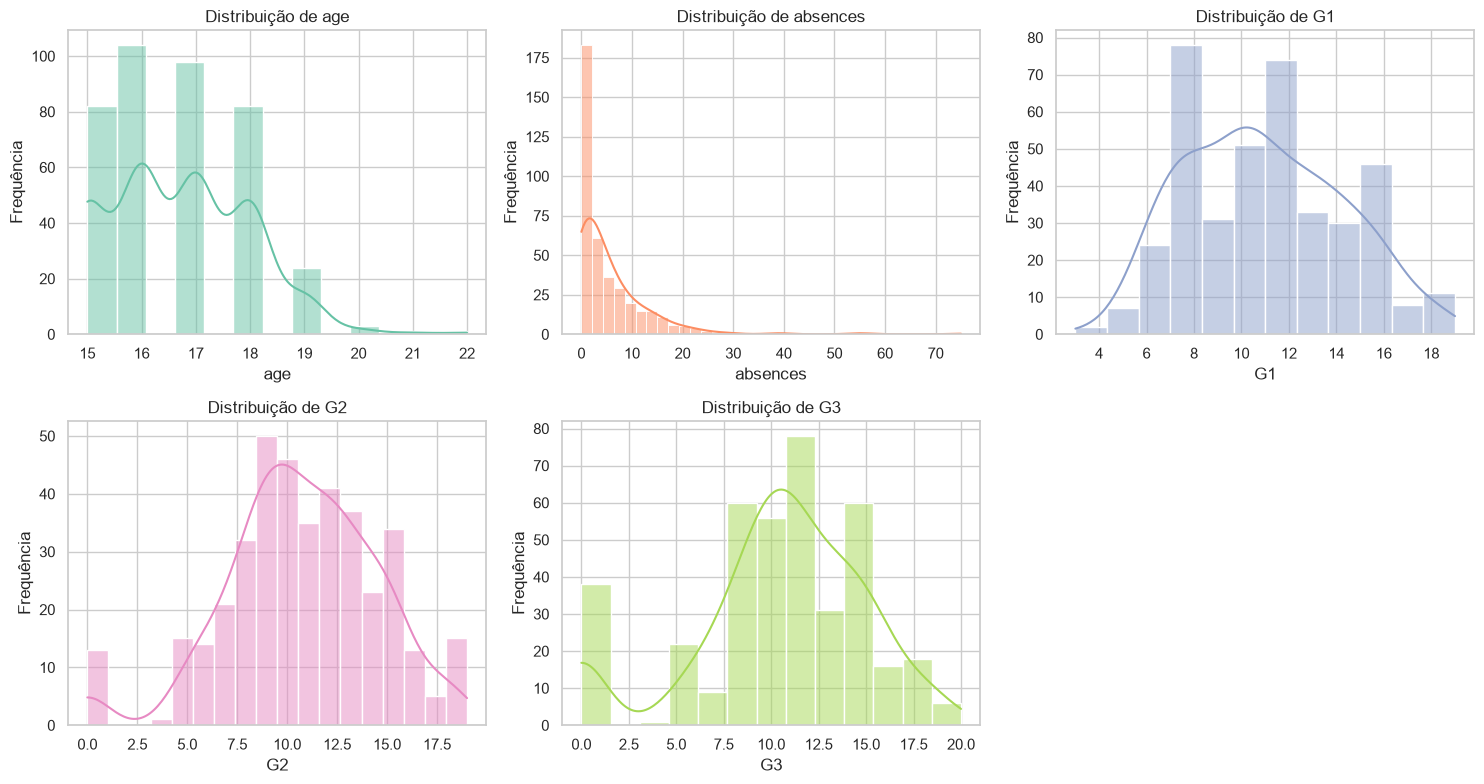

In [36]:
# Histogramas das variáveis numéricas
cores = sns.color_palette("Set2", n_colors=len(variaveis_numericas))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for coluna, cor, ax in zip(variaveis_numericas, cores, axes.flatten()):
    sns.histplot(
        data=df,
        x=coluna,
        kde=True,
        color=cor,
        ax=ax
    )

    ax.set_title(f"Distribuição de {coluna}", fontsize=12)
    ax.set_xlabel(coluna)
    ax.set_ylabel("Frequência")

axes.flatten()[-1].remove()

plt.tight_layout()
plt.show()

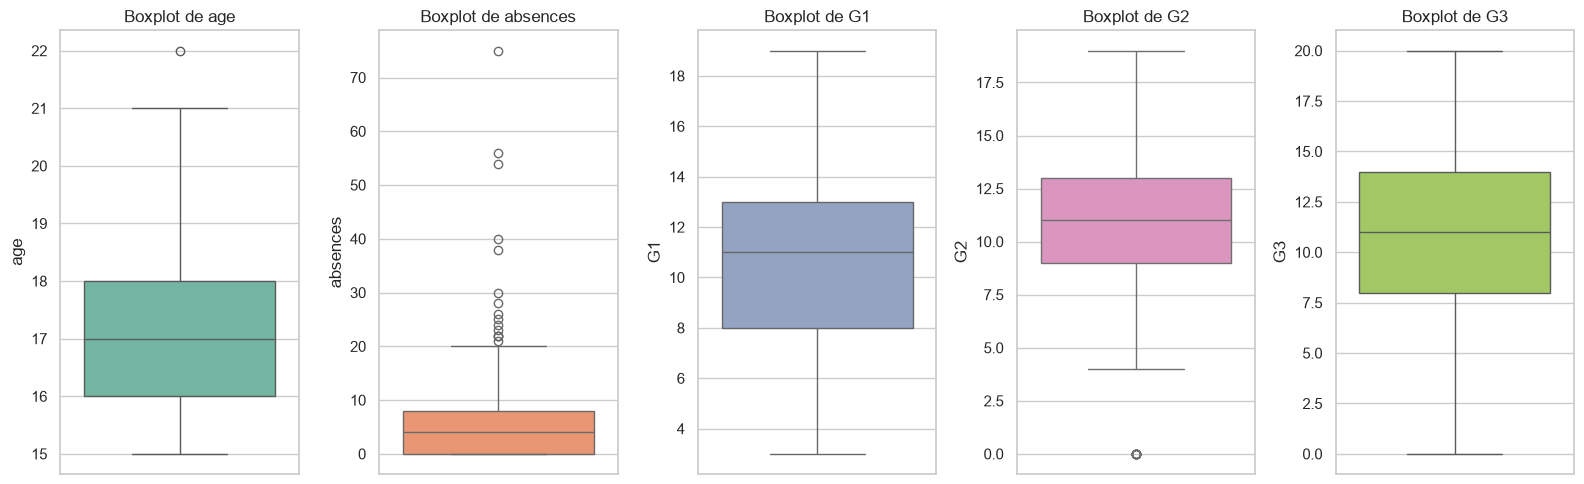

In [37]:
fig, axes = plt.subplots(1, 5, figsize=(16, 5))

for coluna, cor, ax in zip(variaveis_numericas, cores, axes):
    sns.boxplot(data=df, y=coluna, color=cor, ax=ax)
    ax.set_title(f"Boxplot de {coluna}")

plt.tight_layout()
plt.show()

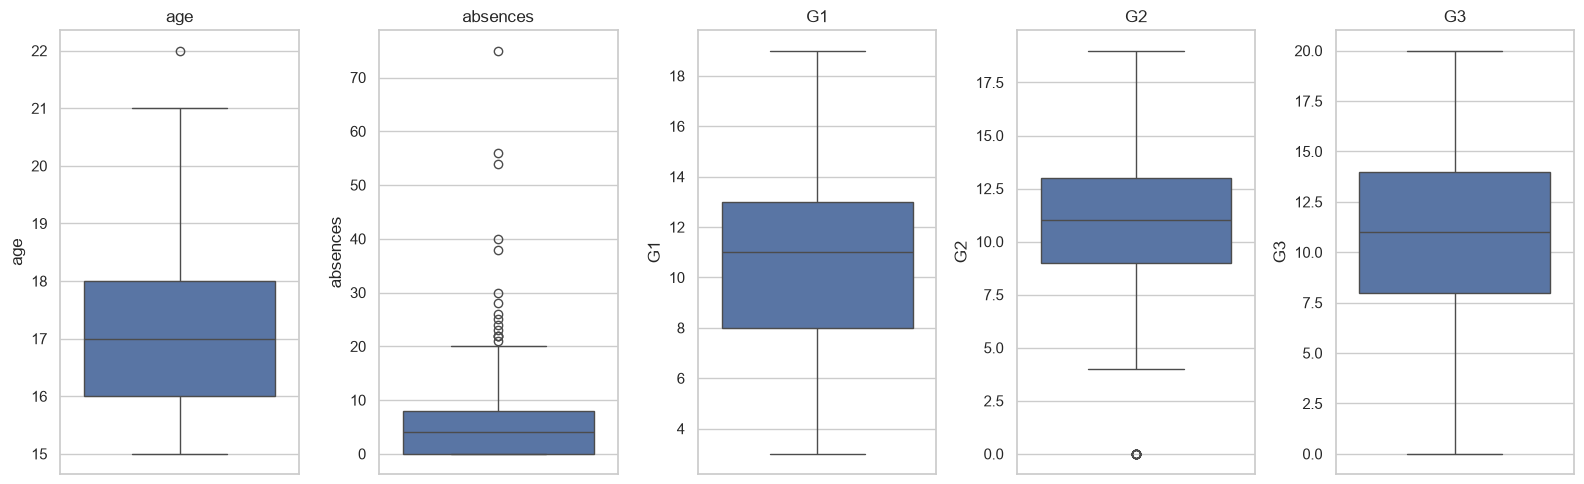

In [38]:
# Boxplots das variáveis numéricas
fig, axes = plt.subplots(1, 5, figsize=(16, 5))

for coluna, ax in zip(variaveis_numericas, axes):
    sns.boxplot(data=df, y=coluna, ax=ax)
    ax.set_title(coluna)

plt.tight_layout()
plt.show()

### Análise univariada das variáveis numéricas

A análise das distribuições numéricas permitiu identificar características importantes sobre o perfil dos estudantes e seu desempenho acadêmico.

A variável `age` apresenta baixa dispersão, com concentração de estudantes entre 15 e 18 anos. Já a variável `absences` possui forte assimetria positiva, indicando que a maioria dos estudantes apresenta poucas faltas, enquanto uma parcela reduzida registra quantidades significativamente superiores.

Em relação às notas, as variáveis `G1`, `G2` e `G3` apresentam concentrações próximas à faixa intermediária da escala. Observa-se também um aumento da dispersão entre os períodos, especialmente na nota final (`G3`).

Os boxplots complementam essa análise ao evidenciar possíveis valores extremos, principalmente nas variáveis `absences`, `age` e `G2`. Esses registros serão mantidos inicialmente, pois a identificação de um outlier estatístico não significa necessariamente que o dado seja inválido.

Os resultados reforçam a importância de investigar a relação entre frequência escolar, características dos estudantes e desempenho acadêmico nas próximas etapas da análise exploratória.

In [39]:
variaveis_extremos = ["age", "absences", "G2"]

for coluna in variaveis_extremos:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    extremos = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    print(f"\nVariável: {coluna}")
    print(f"Limite inferior: {limite_inferior:.2f}")
    print(f"Limite superior: {limite_superior:.2f}")
    print(f"Quantidade de possíveis outliers: {len(extremos)}")
    print(extremos[[coluna]].value_counts().sort_index())


Variável: age
Limite inferior: 13.00
Limite superior: 21.00
Quantidade de possíveis outliers: 1
age
22     1
Name: count, dtype: int64

Variável: absences
Limite inferior: -12.00
Limite superior: 20.00
Quantidade de possíveis outliers: 15
absences
21          1
22          3
23          1
24          1
25          1
26          1
28          1
30          1
38          1
40          1
54          1
56          1
75          1
Name: count, dtype: int64

Variável: G2
Limite inferior: 3.00
Limite superior: 19.00
Quantidade de possíveis outliers: 13
G2
0     13
Name: count, dtype: int64


In [40]:
# Identificar estudantes com nota zero em G2
alunos_g2_zero = df[df["G2"] == 0]

# Visualizar informações relevantes
colunas_analise = [
    "age",
    "absences",
    "G1",
    "G2",
    "G3"
]

display(
    alunos_g2_zero[colunas_analise]
    .sort_values(["G3", "absences"])
)

# Estatísticas dos estudantes com G2 igual a zero
print("Quantidade de estudantes:", len(alunos_g2_zero))

print("\nDistribuição das notas:")
display(
    alunos_g2_zero[["G1", "G2", "G3"]].describe().T
)

print("\nQuantidade com G1 igual a zero:",
      (alunos_g2_zero["G1"] == 0).sum())

print("Quantidade com G3 igual a zero:",
      (alunos_g2_zero["G3"] == 0).sum())

,age,absences,G1,G2,G3
130,15,0,12,0,0
131,15,0,8,0,0
134,15,0,9,0,0
135,15,0,11,0,0
136,17,0,10,0,0
137,16,0,4,0,0
144,17,0,5,0,0
153,19,0,5,0,0
162,16,0,7,0,0
242,16,0,6,0,0


Quantidade de estudantes: 13

Distribuição das notas:


,count,mean,std,min,25%,50%,75%,max
G1,13.0,7.461538,2.43637,4.0,6.0,7.0,9.0,12.0
G2,13.0,0.000000,0.00000,0.0,0.0,0.0,0.0,0.0
G3,13.0,0.000000,0.00000,0.0,0.0,0.0,0.0,0.0



Quantidade com G1 igual a zero: 0
Quantidade com G3 igual a zero: 13


### Análise dos possíveis outliers

A identificação foi realizada pelo método IQR (Intervalo Interquartil), que apontou possíveis valores extremos em três variáveis:

- **`age`:** foi identificado um registro de 22 anos, ligeiramente acima do limite superior de 21 anos.
- **`absences`:** foram encontrados 15 registros acima do limite superior de 20 faltas, chegando a 75 ausências.
- **`G2`:** foram identificados 13 registros com nota zero, abaixo do limite inferior de 3 pontos.

Os valores encontrados foram mantidos na base, pois a identificação estatística de outliers não significa necessariamente que sejam erros ou dados inválidos. Dessa forma, evitamos excluir informações que podem ser relevantes para a análise do desempenho acadêmico.

**Conclusão:** a base apresenta alguns valores extremos, principalmente nas variáveis `absences` e `G2`, mas não foi realizada remoção ou substituição desses registros nesta etapa.

#### 5.1.2.  Análise das Variáveis Qualitativas

Nesta etapa, serão analisadas as distribuições das variáveis categóricas, utilizando tabelas de frequência absoluta e relativa, além de gráficos de barras para identificar a representatividade de cada categoria na base de dados.

In [41]:
# Tabela resumida de frequência das variáveis qualitativas

resultado = (
    df[variaveis_categoricas]
    .melt(var_name="Variável", value_name="Categoria")
    .groupby(["Variável", "Categoria"])
    .size()
    .reset_index(name="Frequência")
)

# Categoria mais frequente de cada variável

resumo = (
    resultado.loc[
        resultado.groupby("Variável")["Frequência"].idxmax()
    ]
    .sort_values("Variável")
    .reset_index(drop=True)
)

display(resumo)

,Variável,Categoria,Frequência
0,Fjob,other,217
1,Mjob,other,141
2,Pstatus,T,354
3,activities,yes,201
4,address,U,307
5,famsize,GT3,281
6,famsup,yes,242
7,guardian,mother,273
8,higher,yes,375
9,internet,yes,329


### Interpretação das variáveis qualitativas

A análise das variáveis qualitativas permitiu identificar as categorias predominantes no perfil dos estudantes:

- **Escola (`school`):** predominância da escola GP, representando 349 estudantes.
- **Sexo (`sex`):** maior presença de estudantes do sexo feminino, com 208 registros.
- **Endereço (`address`):** predominância de estudantes da categoria U, com 307 registros.
- **Tamanho familiar (`famsize`):** maior concentração de famílias com mais de três integrantes (GT3), totalizando 281 estudantes.
- **Apoio familiar (`famsup`):** 242 estudantes declararam receber apoio educacional da família.
- **Responsável (`guardian`):** a categoria mãe apresenta maior frequência, com 273 registros.
- **Escolaridade superior (`higher`):** 375 estudantes demonstraram interesse em continuar os estudos.
- **Acesso à internet (`internet`):** 329 estudantes possuem acesso à internet.
- **Atividades extracurriculares (`activities`):** a distribuição é relativamente equilibrada, com 201 respostas positivas.
- **Apoio escolar (`schoolsup`):** a maioria dos estudantes, 344 registros, não recebe apoio escolar adicional.

**Conclusão:** observa-se uma predominância de determinadas categorias, principalmente nas variáveis relacionadas à escola, continuidade dos estudos, acesso à internet e localização dos estudantes. Essas características ajudam a compreender o perfil geral da amostra e fornecem informações importantes para as próximas etapas da análise exploratória.

É importante destacar que essas frequências representam características descritivas da amostra e, isoladamente, não permitem estabelecer relações de causa e efeito com o desempenho acadêmico.

#### 5.2 Análise Bivariada

Nesta etapa, serão investigadas relações entre pares de variáveis, buscando identificar padrões, associações e possíveis fatores relacionados ao desempenho dos estudantes.


5.2.1. Relação entre Variáveis Quantitativas

Primeiramente, vamos analisar a correlação entre as variáveis quantitativas principais:
- age: idade;
- absences: quantidade de faltas;
- G1: nota do primeiro período;
- G2: nota do segundo período;
- G3: nota final.

In [42]:
# 5.2.1. Matriz de correlação entre variáveis quantitativas

variaveis_correlacao = ["age", "absences", "G1", "G2", "G3"]

matriz_correlacao = df[variaveis_correlacao].corr()

display(matriz_correlacao.round(2))

,age,absences,G1,G2,G3
age,1.00,0.18,-0.06,-0.14,-0.16
absences,0.18,1.00,-0.03,-0.03,0.03
G1,-0.06,-0.03,1.00,0.85,0.80
G2,-0.14,-0.03,0.85,1.00,0.90
G3,-0.16,0.03,0.80,0.90,1.00


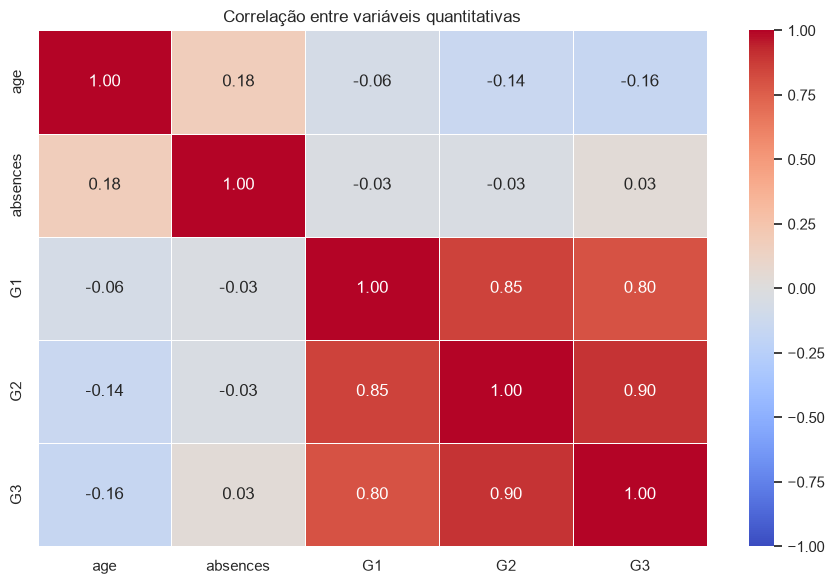

In [43]:
# Mapa de calor da matriz de correlação

plt.figure(figsize=(9, 6))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlação entre variáveis quantitativas")
plt.tight_layout()
plt.show()

In [44]:
# Proporção de estudantes com nota 10

for coluna in ["G1", "G2", "G3"]:
    quantidade = (df[coluna] == 10).sum()
    percentual = quantidade / len(df) * 100

    print(
        f"{coluna}: {quantidade} estudantes "
        f"({percentual:.2f}%)"
    )

G1: 51 estudantes (12.91%)
G2: 46 estudantes (11.65%)
G3: 56 estudantes (14.18%)


In [45]:
# Comparação entre correlações de Pearson e Spearman

pearson = df[["G1", "G2", "G3"]].corr(method="pearson")
spearman = df[["G1", "G2", "G3"]].corr(method="spearman")

print("Correlação de Pearson:")
display(pearson.round(2))

print("Correlação de Spearman:")
display(spearman.round(2))

Correlação de Pearson:


,G1,G2,G3
G1,1.00,0.85,0.8
G2,0.85,1.00,0.9
G3,0.80,0.90,1.0


Correlação de Spearman:


,G1,G2,G3
G1,1.00,0.89,0.88
G2,0.89,1.00,0.96
G3,0.88,0.96,1.00


### Interpretação da correlação entre variáveis quantitativas

A matriz de correlação revelou associações positivas muito fortes entre as notas dos diferentes períodos escolares. Pela correlação de Pearson, foram identificados os seguintes resultados:

- **G1 e G2:** correlação de 0,85, indicando forte associação positiva entre as avaliações.
- **G1 e G3:** correlação de 0,80, demonstrando que o desempenho no primeiro período está associado à nota final.
- **G2 e G3:** correlação de 0,90, representando a associação mais elevada pelo método de Pearson.

Para complementar a investigação, foi utilizada a correlação de Spearman, que apresentou resultados de 0,89 entre G1 e G2, 0,88 entre G1 e G3 e 0,96 entre G2 e G3.

A proximidade entre os resultados dos dois métodos reforça a consistência das associações identificadas. Destaca-se a relação entre G2 e G3, que apresentou a maior intensidade, sugerindo que o desempenho no segundo período está fortemente associado ao resultado final.

Em contrapartida, as variáveis idade e faltas apresentaram correlações lineares fracas com as notas, não indicando associações expressivas nesta análise.

**Conclusão:** os resultados apontam que as notas dos períodos anteriores possuem forte associação com o desempenho final dos estudantes. Essa descoberta será relevante para as próximas etapas da mineração de dados, especialmente na seleção de atributos e na construção de modelos preditivos.

É importante ressaltar que correlação representa associação estatística e não comprova causalidade.

#### 5.2.2. Relação entre Variáveis Qualitativas
Agora vamos investigar associações entre características categóricas dos estudantes, utilizando tabelas de contingência (Crosstab).

Vamos começar analisando:
- Sexo × desempenho acadêmico;
- Apoio escolar × desempenho acadêmico;
- Tempo de estudo × desempenho acadêmico;
- Histórico de reprovações × desempenho acadêmico.



KeyError: 'desempenho'

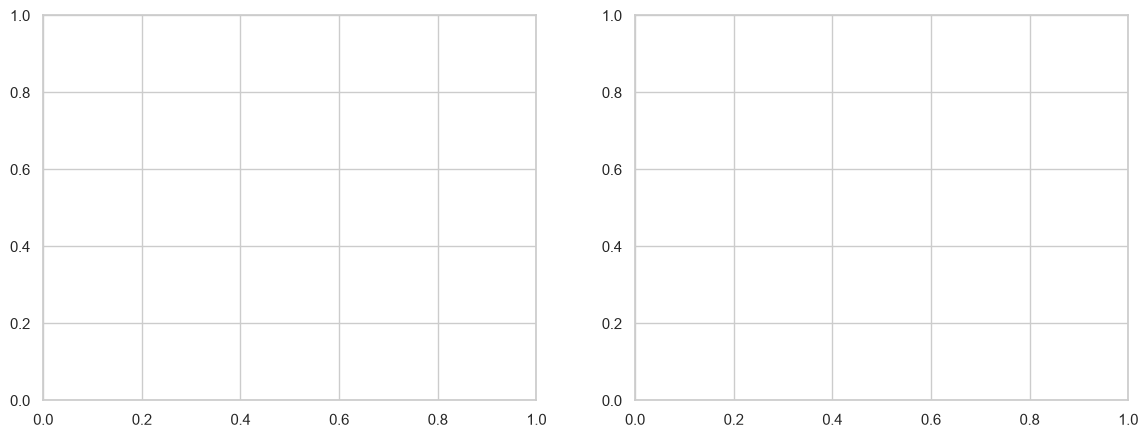

In [46]:
# Relação entre sexo e desempenho acadêmico

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tabela de contingência
tabela_sexo = pd.crosstab(
    df["sex"],
    df["desempenho"],
    normalize="index"
) * 100

sns.heatmap(
    tabela_sexo,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("Distribuição percentual por sexo")
axes[0].set_xlabel("Desempenho")
axes[0].set_ylabel("Sexo")

# Gráfico de barras empilhadas
tabela_sexo.plot(
    kind="bar",
    stacked=True,
    color=sns.color_palette("Set2", 2),
    ax=axes[1]
)

axes[1].set_title("Desempenho acadêmico por sexo")
axes[1].set_xlabel("Sexo")
axes[1].set_ylabel("Percentual (%)")
axes[1].legend(title="Desempenho")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# Tabela de contingência: sexo x desempenho

tabela_sexo = pd.crosstab(
    df["sex"],
    df["desempenho"],
    normalize="index"
) * 100

display(tabela_sexo.round(2))

desempenho,Aprovado,Não aprovado
sex,,
F,63.94,36.06
M,70.59,29.41


### Análise da relação entre sexo e desempenho acadêmico

A análise da relação entre sexo e desempenho acadêmico revelou diferenças na distribuição percentual dos resultados entre os grupos.

Entre os estudantes do sexo feminino, 63,9% foram classificados como aprovados e 36,1% como não aprovados. Já entre os estudantes do sexo masculino, o percentual de aprovação foi de 70,6%, enquanto 29,4% foram classificados como não aprovados.

Observa-se uma diferença de 6,7 pontos percentuais na taxa de aprovação, com maior percentual no grupo masculino. Apesar dessa diferença, ambos os grupos apresentaram predominância de estudantes aprovados.

**Conclusão:** os resultados indicam uma diferença descritiva no desempenho acadêmico entre os grupos analisados. Entretanto, essa associação não permite estabelecer uma relação de causalidade entre sexo e desempenho escolar.

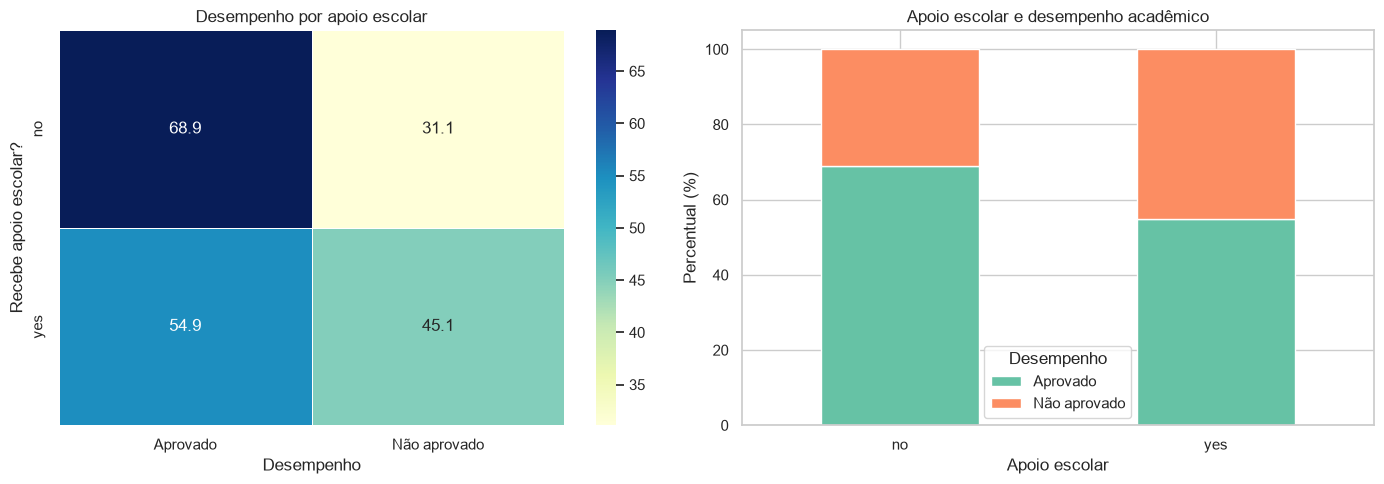

In [ ]:
# Relação entre apoio escolar e desempenho acadêmico

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tabela_apoio = pd.crosstab(
    df["schoolsup"],
    df["desempenho"],
    normalize="index"
) * 100

# Heatmap
sns.heatmap(
    tabela_apoio,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("Desempenho por apoio escolar")
axes[0].set_xlabel("Desempenho")
axes[0].set_ylabel("Recebe apoio escolar?")

# Gráfico de barras empilhadas
tabela_apoio.plot(
    kind="bar",
    stacked=True,
    color=sns.color_palette("Set2", 2),
    ax=axes[1]
)

axes[1].set_title("Apoio escolar e desempenho acadêmico")
axes[1].set_xlabel("Apoio escolar")
axes[1].set_ylabel("Percentual (%)")
axes[1].legend(title="Desempenho")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Análise da relação entre apoio escolar e desempenho acadêmico

A análise da relação entre o recebimento de apoio escolar adicional (`schoolsup`) e o desempenho acadêmico revelou diferenças entre os grupos.

Entre os estudantes que não recebem apoio escolar, 68,9% foram classificados como aprovados e 31,1% como não aprovados. Já entre aqueles que recebem apoio adicional, o percentual de aprovação foi de 54,9%, enquanto 45,1% foram classificados como não aprovados.

Observa-se uma diferença de 14 pontos percentuais na taxa de aprovação, com maior percentual entre os estudantes que não recebem apoio adicional.

Entretanto, esse resultado deve ser interpretado com cautela. Uma possível explicação é que estudantes com dificuldades acadêmicas tenham maior probabilidade de receber apoio escolar, o que pode influenciar a distribuição observada. Além disso, os grupos apresentam tamanhos diferentes, sendo 344 estudantes sem apoio e 51 com apoio.

**Conclusão:** os dados demonstram uma associação entre o recebimento de apoio escolar adicional e a distribuição do desempenho acadêmico. Contudo, não é possível concluir que o apoio cause uma redução no desempenho, pois outras características dos estudantes podem estar relacionadas a essa diferença.

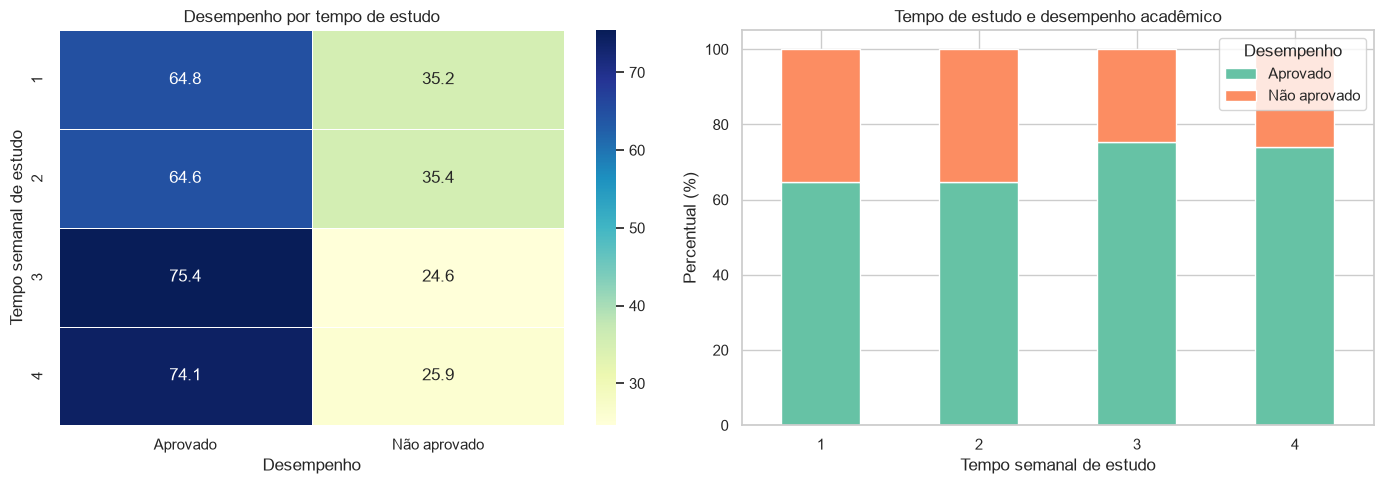

In [ ]:
# Relação entre tempo de estudo e desempenho acadêmico

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tabela_estudo = pd.crosstab(
    df["studytime"],
    df["desempenho"],
    normalize="index"
) * 100

# Heatmap
sns.heatmap(
    tabela_estudo,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("Desempenho por tempo de estudo")
axes[0].set_xlabel("Desempenho")
axes[0].set_ylabel("Tempo semanal de estudo")

# Barras empilhadas
tabela_estudo.plot(
    kind="bar",
    stacked=True,
    color=sns.color_palette("Set2", 2),
    ax=axes[1]
)

axes[1].set_title("Tempo de estudo e desempenho acadêmico")
axes[1].set_xlabel("Tempo semanal de estudo")
axes[1].set_ylabel("Percentual (%)")
axes[1].legend(title="Desempenho")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Análise da relação entre tempo de estudo e desempenho acadêmico

A análise da relação entre o tempo semanal dedicado aos estudos (`studytime`) e o desempenho acadêmico revelou diferenças entre as categorias investigadas.

Entre os estudantes que estudam menos de duas horas por semana, o percentual de aprovação foi de 64,8%. Na categoria de duas a cinco horas, esse percentual foi de 64,6%, apresentando resultados bastante semelhantes.

Já entre os estudantes que dedicam de cinco a dez horas semanais aos estudos, a aprovação alcançou 75,4%. Para aqueles que estudam mais de dez horas, o percentual foi de 74,1%.

Observa-se que as categorias com maior dedicação semanal aos estudos apresentaram percentuais de aprovação superiores aos grupos com menor tempo de estudo. Entretanto, não foi identificada uma progressão contínua, pois a categoria de cinco a dez horas apresentou resultado ligeiramente superior à categoria de mais de dez horas.

**Conclusão:** os resultados sugerem uma associação positiva entre maior dedicação semanal aos estudos e desempenho acadêmico. Contudo, essa relação deve ser interpretada com cautela, considerando a distribuição de estudantes entre as categorias e a possível influência de outros fatores sobre os resultados escolares. A análise não permite estabelecer uma relação de causalidade.

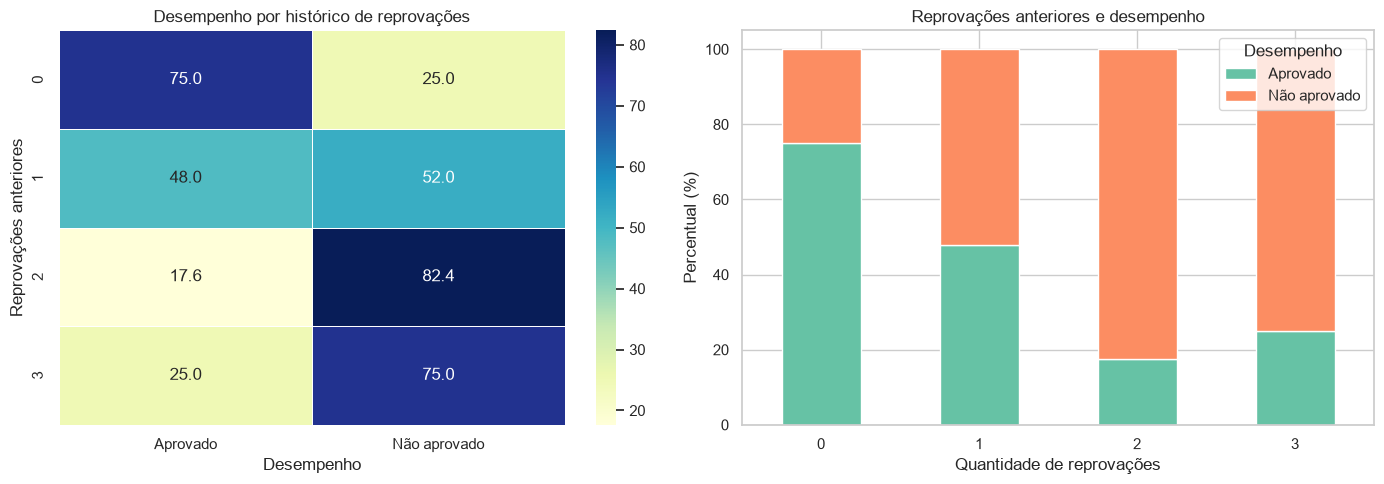

In [ ]:
# Relação entre reprovações anteriores e desempenho acadêmico

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tabela_reprovacoes = pd.crosstab(
    df["failures"],
    df["desempenho"],
    normalize="index"
) * 100

# Heatmap
sns.heatmap(
    tabela_reprovacoes,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("Desempenho por histórico de reprovações")
axes[0].set_xlabel("Desempenho")
axes[0].set_ylabel("Reprovações anteriores")

# Gráfico de barras empilhadas
tabela_reprovacoes.plot(
    kind="bar",
    stacked=True,
    color=sns.color_palette("Set2", 2),
    ax=axes[1]
)

axes[1].set_title("Reprovações anteriores e desempenho")
axes[1].set_xlabel("Quantidade de reprovações")
axes[1].set_ylabel("Percentual (%)")
axes[1].legend(title="Desempenho")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Análise da relação entre histórico de reprovações e desempenho acadêmico

A análise da relação entre a quantidade de reprovações anteriores (`failures`) e o desempenho acadêmico revelou diferenças expressivas entre os grupos.

Entre os estudantes sem reprovações anteriores, 75% foram classificados como aprovados e 25% como não aprovados. Para aqueles com uma reprovação, o percentual de aprovação foi de 48%, enquanto 52% não foram aprovados.

A diferença torna-se ainda mais evidente entre os estudantes com duas reprovações anteriores, dos quais apenas 17,6% foram aprovados. Na categoria de três reprovações, o percentual de aprovação foi de 25%, enquanto 75% foram classificados como não aprovados.

Observa-se uma tendência geral de redução do percentual de aprovação conforme aumenta o histórico de reprovações. Entretanto, a categoria de três reprovações apresentou resultado ligeiramente superior à de duas reprovações.

**Conclusão:** o histórico de reprovações apresenta uma associação relevante com o desempenho acadêmico atual. Os resultados sugerem que estudantes com maior quantidade de reprovações anteriores tendem a apresentar maiores dificuldades na avaliação final. Essa variável demonstra potencial relevância para as próximas etapas da mineração de dados, especialmente na seleção de atributos para modelos preditivos.

É importante considerar a quantidade de estudantes em cada categoria e destacar que a associação observada não comprova causalidade.

In [ ]:
# Quantidade de estudantes por histórico de reprovações

display(
    df["failures"]
    .value_counts()
    .sort_index()
    .to_frame("Quantidade de estudantes")
)

,Quantidade de estudantes
failures,
0,312
1,50
2,17
3,16


#### 5.2.3. Relação entre variáveis quantitativas e qualitativas
Nesta etapa, vamos investigar como as notas dos estudantes (G1, G2 e G3) variam conforme determinadas características categóricas.

Como temos muitas variáveis qualitativas, vamos selecionar inicialmente algumas que podem oferecer interpretações relevantes:
- sex: sexo do estudante;
- schoolsup: recebimento de apoio escolar;
- famsup: apoio educacional da família;
- higher: intenção de cursar ensino superior;
- internet: acesso à internet;
- address: localização da residência.

In [ ]:
# Variáveis qualitativas selecionadas
variaveis_categoria = [
    "sex", "schoolsup", "famsup",
    "higher", "internet", "address"
]


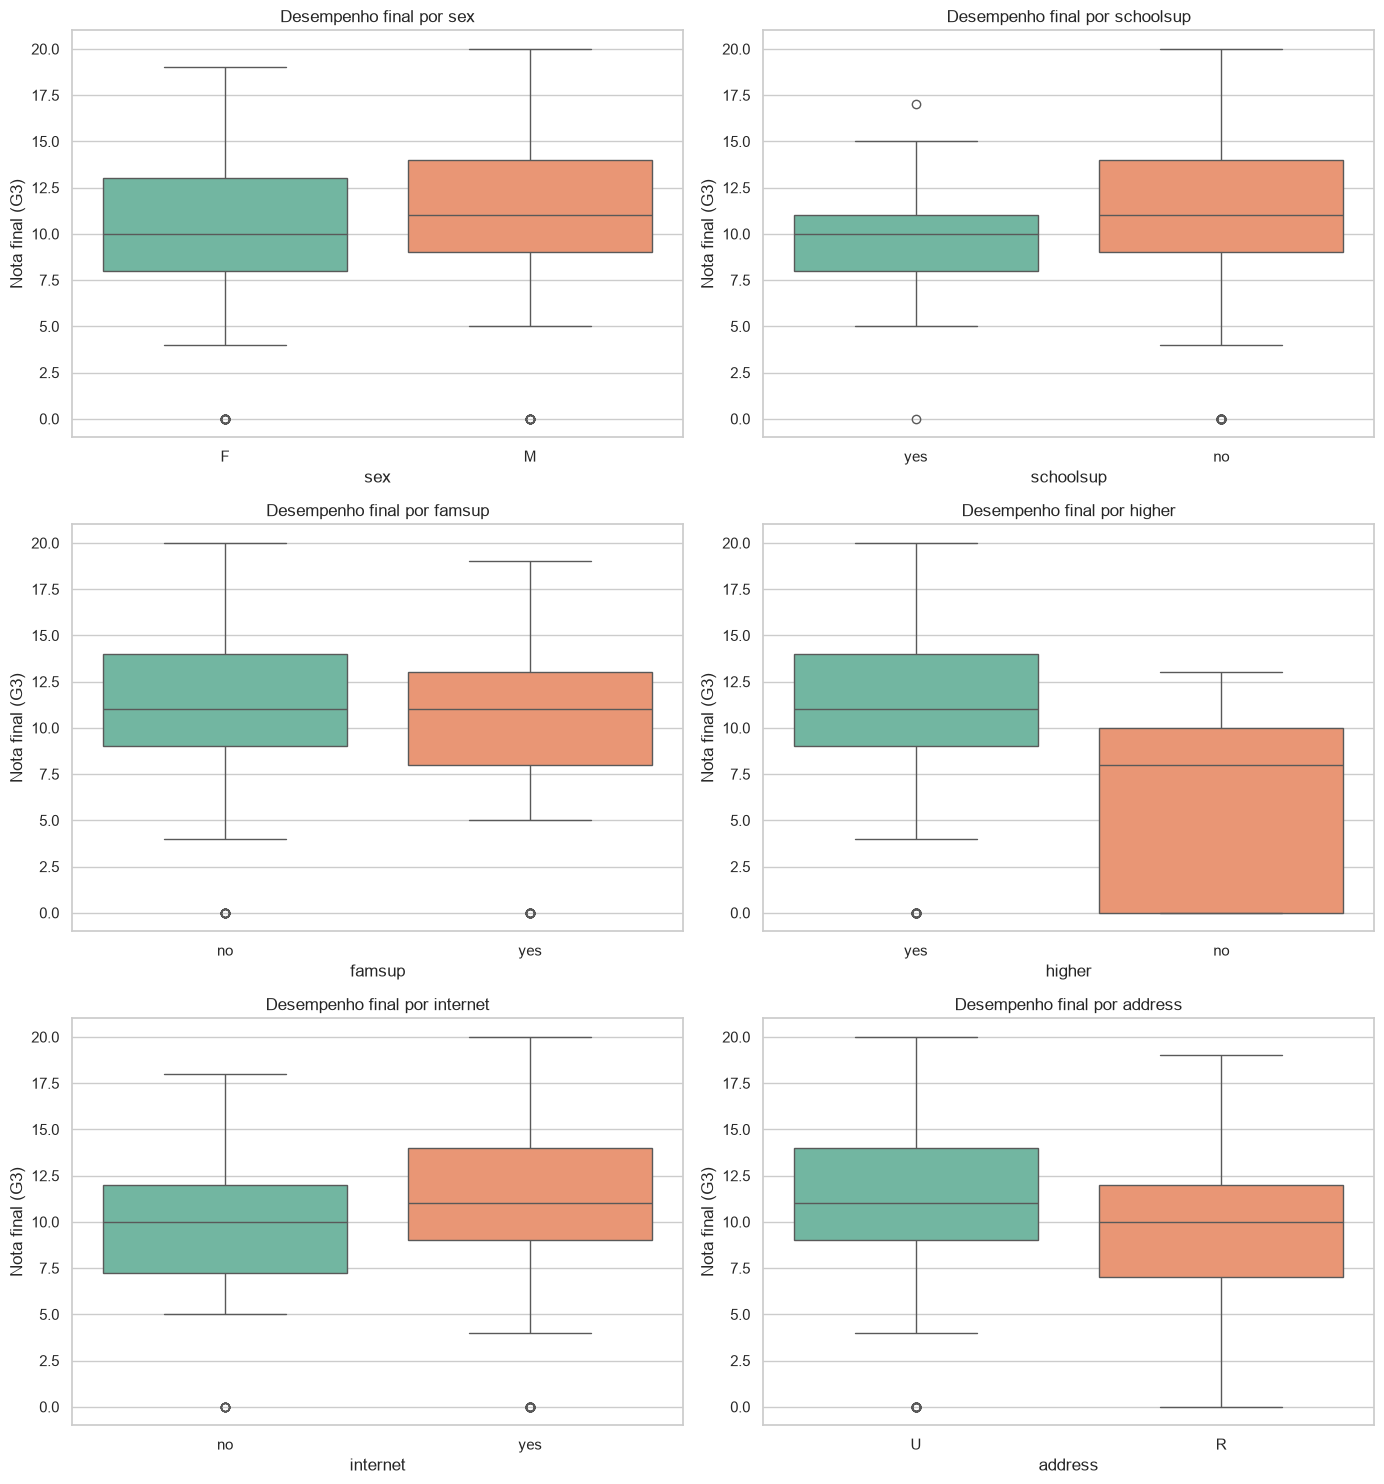

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for coluna, ax in zip(variaveis_categoria, axes.flatten()):
    sns.boxplot(
        data=df,
        x=coluna,
        y="G3",
        hue=coluna,
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(f"Desempenho final por {coluna}")
    ax.set_xlabel(coluna)
    ax.set_ylabel("Nota final (G3)")

plt.tight_layout()
plt.show()

A análise dos boxplots permite observar diferenças na distribuição das notas finais (G3) conforme determinadas características dos estudantes.

- **Sexo (`sex`):** os estudantes do sexo masculino apresentam mediana ligeiramente superior à das estudantes do sexo feminino. Entretanto, as distribuições são relativamente próximas, indicando que a diferença entre os grupos não é muito expressiva.

- **Apoio escolar (`schoolsup`):** os estudantes que não recebem apoio escolar apresentam mediana de desempenho ligeiramente superior. Esse resultado não significa que o apoio escolar prejudique o desempenho, pois estudantes com maiores dificuldades podem ter maior probabilidade de receber esse suporte.

- **Apoio familiar (`famsup`):** os grupos apresentam medianas semelhantes, sugerindo que, isoladamente, essa variável não demonstra uma diferença expressiva nas notas finais.

- **Intenção de cursar ensino superior (`higher`):** observa-se uma diferença relevante entre os grupos. Os estudantes que pretendem cursar o ensino superior apresentam mediana de notas superior àqueles que não possuem essa intenção. Esse comportamento sugere uma associação entre essa característica e o desempenho acadêmico.

- **Acesso à internet (`internet`):** os estudantes com acesso à internet apresentam mediana ligeiramente superior. Apesar disso, existe sobreposição considerável entre as distribuições dos grupos.

- **Localização da residência (`address`):** os estudantes residentes em áreas urbanas apresentam mediana de desempenho ligeiramente superior à dos estudantes de áreas rurais. Entretanto, as distribuições também apresentam sobreposição.

**Conclusão:** entre as variáveis analisadas, a intenção de cursar o ensino superior (`higher`) apresenta uma das diferenças mais evidentes em relação às notas finais. As demais variáveis apresentam diferenças menores ou distribuições bastante semelhantes. Esses resultados representam associações observadas na base, não relações de causalidade.

#### 5.2.4.1. Relação entre as notas e características dos estudantes

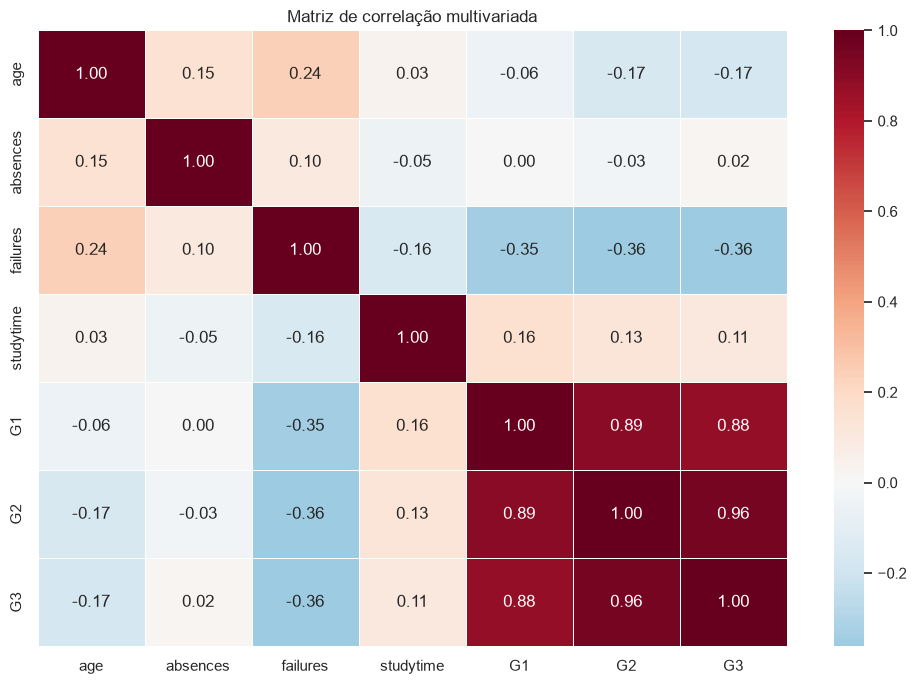

In [ ]:
# Seleção de variáveis para análise multivariada
variaveis_multi = [
    "age", "absences", "failures",
    "studytime", "G1", "G2", "G3"
]

# Matriz de correlação de Spearman
correlacao_multi = df[variaveis_multi].corr(method="spearman")

# Visualização
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacao_multi,
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de correlação multivariada")
plt.tight_layout()
plt.show()

A matriz de correlação de Spearman permite observar a intensidade e a direção das associações entre as variáveis quantitativas e ordinais selecionadas.

Os principais resultados identificados foram:

- **G1, G2 e G3:** apresentam correlações positivas muito fortes, com valores entre 0,88 e 0,96. Isso demonstra uma associação consistente entre as notas dos diferentes períodos avaliativos, indicando que estudantes com melhores resultados nas avaliações anteriores tendem a apresentar melhores resultados nas avaliações seguintes.

- **Histórico de reprovações (`failures`):** apresenta correlação negativa moderada com G1, G2 e G3, com valores de -0,35, -0,36 e -0,36, respectivamente. Esse resultado indica que uma maior quantidade de reprovações anteriores está associada a notas menores.

- **Idade (`age`):** apresenta correlação negativa fraca com G2 e G3, ambas de -0,17. Portanto, a idade apresenta uma associação negativa pouco expressiva com o desempenho acadêmico.

- **Tempo de estudo (`studytime`):** apresenta correlações positivas fracas com as três avaliações, variando entre 0,11 e 0,16. Embora exista uma associação positiva, sua intensidade é baixa.

- **Faltas (`absences`):** apresenta correlações próximas de zero com G1, G2 e G3, indicando uma associação monotônica muito fraca entre a quantidade de faltas e as notas nesta análise.

**Conclusão:** as relações mais expressivas foram observadas entre as notas dos períodos avaliativos e entre o histórico de reprovações e o desempenho acadêmico. Essas variáveis apresentam potencial relevância para as próximas etapas de mineração de dados.

#### 5.2.4.2. Relação conjunta entre reprovações, tempo de estudo e desempenho

studytime,1,2,3,4
failures,,,,
0,11.59,10.82,12.02,11.31
1,8.12,8.15,7.71,10.00
2,2.83,7.29,9.50,NaN
3,5.56,5.86,NaN,NaN


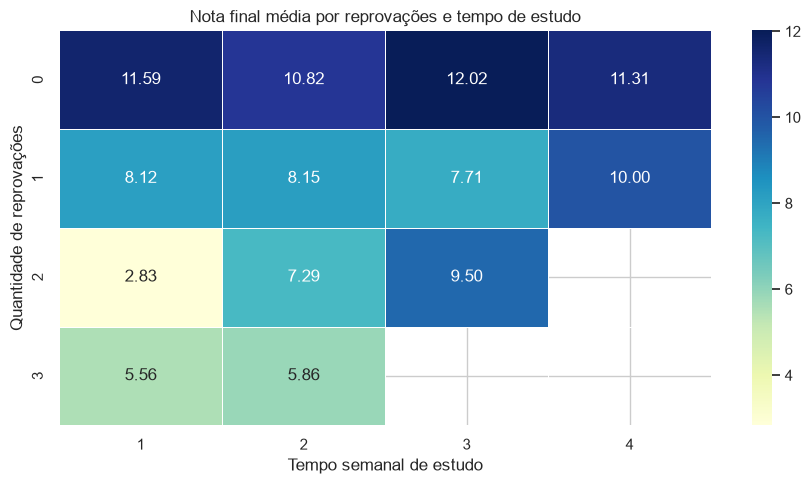

In [ ]:
# Média da nota final por reprovações e tempo de estudo
tabela_multi = pd.pivot_table(
    df,
    values="G3",
    index="failures",
    columns="studytime",
    aggfunc="mean"
)

display(tabela_multi.round(2))

# Visualização
plt.figure(figsize=(9, 5))

sns.heatmap(
    tabela_multi,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Nota final média por reprovações e tempo de estudo")
plt.xlabel("Tempo semanal de estudo")
plt.ylabel("Quantidade de reprovações")

plt.tight_layout()
plt.show()

A análise conjunta entre o histórico de reprovações (`failures`), o tempo semanal de estudo (`studytime`) e a nota final média (G3) permite observar diferenças de desempenho entre os grupos.

Os principais resultados foram:

- **Nenhuma reprovação anterior:** os estudantes apresentam médias entre 10,82 e 12,02, demonstrando os melhores resultados gerais entre as categorias analisadas.

- **Uma reprovação anterior:** as médias variam entre 7,71 e 10,00, indicando desempenho inferior ao grupo sem reprovações.

- **Duas reprovações anteriores:** as médias apresentam maior variação, de 2,83 a 9,50, conforme o tempo semanal de estudo.

- **Três reprovações anteriores:** as médias observadas são 5,56 e 5,86 para uma e duas horas de estudo, respectivamente. Não há registros nas demais combinações.

**Conclusão:** o histórico de reprovações apresenta uma associação relevante com o desempenho acadêmico. Os estudantes sem reprovações anteriores apresentam médias finais superiores na maior parte das combinações observadas.

O tempo semanal de estudo, isoladamente, não apresenta uma tendência uniforme de aumento das notas em todos os grupos. Portanto, é importante considerar a interação entre diferentes características dos estudantes, além de observar a quantidade de registros em cada combinação.

### 5.2.5. Conclusão geral da análise exploratória dos dados (EDA)

A análise exploratória permitiu compreender a estrutura do conjunto de dados, identificar características dos estudantes e investigar possíveis associações entre variáveis pessoais, familiares, sociais e escolares e o desempenho acadêmico.

A base analisada contém **395 registros e 33 variáveis**, sem valores ausentes ou registros duplicados. Nas variáveis quantitativas, foram observadas diferenças de distribuição e valores extremos, principalmente em idade, faltas e avaliações acadêmicas. Esses registros foram mantidos na análise, considerando que podem representar situações reais dos estudantes.

A análise das variáveis categóricas revelou características predominantes na amostra, como maior concentração de estudantes da escola GP, residentes em áreas urbanas e com acesso à internet. Também foram observadas diferenças na distribuição de características familiares, escolares e comportamentais.

Nas análises bivariadas e multivariadas, destacaram-se as associações entre as notas G1, G2 e G3, que apresentaram forte correlação positiva. O histórico de reprovações anteriores (`failures`) também demonstrou associação com o desempenho acadêmico, enquanto outras variáveis, como faltas (`absences`), tempo de estudo (`studytime`) e intenção de cursar o ensino superior (`higher`), contribuíram para ampliar a compreensão do perfil dos estudantes.

As análises indicaram que o desempenho acadêmico está relacionado a diferentes características observadas no conjunto de dados. Entretanto, essas associações não representam relações de causa e efeito e devem ser interpretadas considerando as limitações da amostra.

**Conclusão final:** a EDA identificou as notas dos períodos anteriores e o histórico de reprovações como características particularmente relevantes para investigar o desempenho acadêmico. Os resultados também evidenciaram a importância de considerar variáveis pessoais, familiares e comportamentais na análise.

Dessa forma, a etapa exploratória forneceu subsídios para a preparação dos dados e a seleção das variáveis utilizadas na etapa seguinte de modelagem preditiva.